# Pictures and series

A port can carry a picture (`element_51.Image`, up to 256 by 256 pixels, grey or
colour) or a series of numbers (`element_51.Series`, up to 100,000 values). The
editor draws a picture on its card and a series as a line. This notebook builds
a grey ramp and its negative, a loss curve that blows up halfway, and draws both
here so you can judge them by eye. It also shows what a picture with the wrong
number of pixels gets.

In [1]:
# Standard library
import io
import math

In [2]:
# Third-party libraries
import matplotlib.pyplot as plt
from IPython import display as ipython_display
from PIL import Image as PilImage

In [3]:
# Local libraries
import element_51

In [4]:
# The sizes are small so the saved notebook stays small
SIDE = 28
STEPS = 60
BLOW_UP_AT = 40
MAX_BRIGHTNESS = 255

## A picture and its negative

In [5]:
@element_51.node
def ramp(side: int = SIDE) -> element_51.Image:
    row = bytes(
        column * MAX_BRIGHTNESS // max(side - 1, 1) for column in range(side)
    )
    return element_51.Image(
        width=side, height=side, channels=1, pixels=row * side
    )


@element_51.node
def invert(source: element_51.Image) -> element_51.Image:
    return element_51.Image(
        width=source.width,
        height=source.height,
        channels=source.channels,
        pixels=bytes(MAX_BRIGHTNESS - pixel for pixel in source.pixels),
    )


app = element_51.App([ramp, invert])
n_ramp = app.add_node(ramp, x=60.0, y=80.0)
n_invert = app.add_node(invert, x=320.0, y=80.0)
app.add_link(n_ramp, "out", n_invert, "source")
results = app.run()
original = results[n_ramp]["out"]
negative = results[n_invert]["out"]
assert isinstance(original, element_51.Image)
assert isinstance(negative, element_51.Image)
print(
    type(original).__name__,
    original.width,
    "x",
    original.height,
    original.channels,
    "channel",
)

Image 28 x 28 1 channel


Both pictures, enlarged so the pixels are visible:

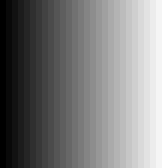

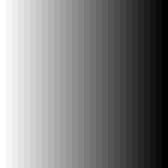

In [6]:
def show(picture: element_51.Image, zoom: int = 6) -> None:
    mode = "L" if picture.channels == 1 else "RGB"
    pil = PilImage.frombytes(
        mode, (picture.width, picture.height), picture.pixels
    )
    pil = pil.resize(
        (picture.width * zoom, picture.height * zoom),
        PilImage.Resampling.NEAREST,
    )
    buffer = io.BytesIO()
    pil.save(buffer, format="PNG")
    ipython_display.display(ipython_display.Image(data=buffer.getvalue()))


show(original)
show(negative)
assert original.pixels[0] == 0
assert negative.pixels[0] == MAX_BRIGHTNESS
assert original.pixels[SIDE - 1] == MAX_BRIGHTNESS

## A series

A node returns a `Series` and the editor draws it as a line against its position.
NaN is a gap in the line, so a loss that diverges does not break anything.

In [7]:
@element_51.node
def training(steps: int = STEPS) -> element_51.Series:
    return element_51.Series(
        values=tuple(
            math.nan if step >= BLOW_UP_AT else 1.0 / (1 + step)
            for step in range(steps)
        )
    )


curves = element_51.App([training])
n_training = curves.add_node(training, x=60.0, y=80.0)
loss = curves.run()[n_training]["out"]
assert isinstance(loss, element_51.Series)
print(
    len(loss.values),
    "values, the last finite one is",
    loss.values[BLOW_UP_AT - 1],
)

60 values, the last finite one is 0.025


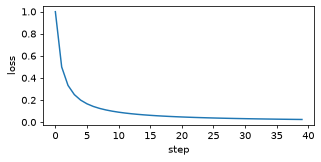

In [8]:
figure, axis = plt.subplots(figsize=(5, 2.2))
axis.plot(loss.values)
axis.set_xlabel("step")
axis.set_ylabel("loss")
buffer = io.BytesIO()
figure.savefig(buffer, format="png", dpi=70, bbox_inches="tight")
plt.close(figure)
ipython_display.display(ipython_display.Image(data=buffer.getvalue()))
assert len(loss.values) == STEPS
assert math.isnan(loss.values[BLOW_UP_AT])
assert not math.isnan(loss.values[BLOW_UP_AT - 1])

## A picture that does not add up

The pixels must fill the picture exactly: `width * height * channels` bytes.

In [9]:
refused = False
try:
    element_51.Image(width=2, height=2, channels=1, pixels=b"\x00\x01\x02")
except ValueError as error:
    refused = True
    print(error)
assert refused

1 validation error for Image
  Value error, pixels: 2 by 2 with 1 channel(s) needs 4 values, got 3 [type=value_error, input_value={'width': 2, 'height': 2,...ixels': b'\x00\x01\x02'}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.14/v/value_error
